<a href="https://colab.research.google.com/github/jc020230/forecasting/blob/main/midterm_q2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 중간고사 대체 과제 — 문제 2: 서울 월별 도시가스 판매량 (1989.01–2024.12)
**자료**: 공공데이터포털, 한국가스공사_월별 시도별 도시가스 판매현황 (https://www.data.go.kr/data/15040819/fileData.do), 서울 열, 단위 천㎥(원자료 그대로)

코드는 수업 lab 노트북([github.com/bcseong2/fpppy-labs](https://github.com/bcseong2/fpppy-labs))의 코드를 그대로 사용했고, 각 셀 제목에 근거 슬라이드를 표시했다.

**실행 전**: 공공데이터포털에서 내려받은 CSV 파일을 Colab 왼쪽 파일 창(`/content`)에 업로드한 뒤 위에서부터 차례로 실행.

In [ ]:
%pip install -q statsforecast utilsforecast statsmodels scipy matplotlib

## Setup (Ch5·Ch8 lab의 Setup 셀)

In [ ]:
import warnings; warnings.filterwarnings("ignore")
import os; os.environ["NIXTLA_ID_AS_COL"] = "true"
import glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from functools import partial
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.seasonal import STL
from scipy.stats import boxcox
from coreforecast.scalers import boxcox_lambda
from statsforecast import StatsForecast
from statsforecast.models import Naive, SeasonalNaive, RandomWalkWithDrift, AutoETS
from statsforecast.utils import ConformalIntervals
from statsmodels.stats.diagnostic import acorr_ljungbox
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import mase, winkler_score
from utilsforecast.losses import mape as _mape
plt.rcParams.update({"figure.figsize": (7, 3.5)})

def mape(df, models, **kw):          # MAPE in percent (Ch8 lab, Slide 21)
    out = _mape(df, models, **kw)
    out[models] *= 100
    return out

## 자료 읽기: 연월 × 시도(wide) → 서울 열을 `unique_id` / `ds` / `y`로 (Ch2 Slide 2 형식)

In [ ]:
FILE = glob.glob("*도시가스*판매현황*.csv")[0]        # 업로드한 공공데이터포털 파일
raw = pd.read_csv(FILE, encoding="cp949")
raw["ds"] = pd.to_datetime(raw["연월"] + "-01")
df = (raw.assign(unique_id="seoul", y=raw["서울"])          # 단위: 천㎥(원자료 그대로)
        [["unique_id", "ds", "y"]]
        .sort_values("ds").reset_index(drop=True))
print(df.head(3)); print(df.tail(3))
print("T =", len(df), "| 결측:", df["y"].isna().sum(), "| 0 이하:", (df["y"] <= 0).sum())

  unique_id         ds      y
0     seoul 1989-01-01  37560
1     seoul 1989-02-01  33566
2     seoul 1989-03-01  30224
    unique_id         ds       y
429     seoul 2024-10-01  119639
430     seoul 2024-11-01  235767
431     seoul 2024-12-01  451637
T = 432 | 결측: 0 | 0 이하: 0


# 문제 2(1) 자료의 특징과 분산안정화 변환 검토
### [Ch2 Slide 8] Time plot

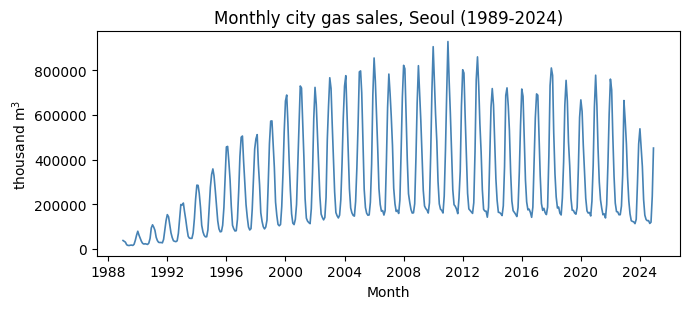

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(df["ds"], df["y"], lw=1.2, color="steelblue")
ax.set(xlabel="Month", ylabel="thousand m$^3$",
       title="Monthly city gas sales, Seoul (1989-2024)")
plt.tight_layout(); plt.show()

### [Ch2 Slide 13] Seasonal plot
연도가 30개 이상이면 alpha를 0.3으로 낮춘다(Slide 15 code notes).

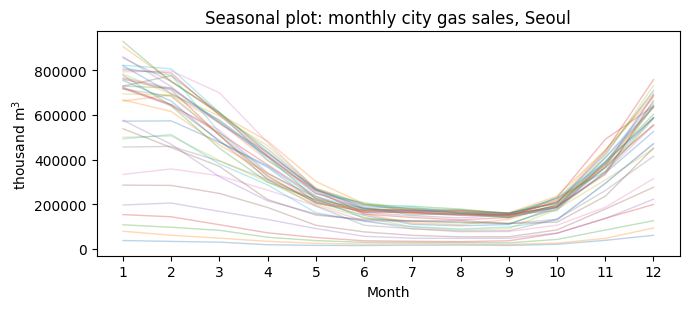

In [ ]:
df["year"]  = df["ds"].dt.year
df["month"] = df["ds"].dt.month

fig, ax = plt.subplots(figsize=(7, 3.2))
for yr, g in df.groupby("year"):
    ax.plot(g["month"], g["y"], lw=1, alpha=0.3, label=str(yr))
ax.set(xlabel="Month", ylabel="thousand m$^3$",
       title="Seasonal plot: monthly city gas sales, Seoul")
ax.set_xticks(range(1, 13))
plt.tight_layout(); plt.show()

### 연간 합계·증가율, 최근 10년 월별 지수, 2023년 시도별 변화율 (Ch2 Slide 6의 groupby 집계)

In [ ]:
annual = df.groupby("year", as_index=False).agg({"y": "sum"})
annual["bn_m3"] = annual["y"] / 1e6                             # 십억㎥
print(annual.iloc[[0, 10, 20, 30, -3, -2, -1]][["year", "bn_m3"]].round(2).to_string(index=False))
print("최대 연간 판매량:", annual.loc[annual["y"].idxmax(), ["year", "bn_m3"]].round(2).to_dict())

growth = annual.set_index("year")["y"].pct_change() * 100      # 연간 증가율(%)
print(); print("10년대별 평균 연간 증가율(%):")
print(growth.groupby((growth.index // 10) * 10).mean().round(1).to_string())

recent = df[df["year"] >= 2015]                                 # 최근 10년
month_idx = (recent["y"] / recent.groupby("year")["y"].transform("mean"))
month_idx = month_idx.groupby(recent["month"]).mean()
print(); print("최근 10년(2015-2024) 월별 지수(연평균 = 1):")
print(month_idx.round(3).to_string())

regions = [c for c in raw.columns if c not in ("연월", "ds")]
by_year = raw.groupby(raw["ds"].dt.year)[regions].sum()
print(); print("2023년 / 2022년 판매량 비율(시도별):")
print((by_year.loc[2023] / by_year.loc[2022]).round(2).to_string())
s23 = df[df["year"] == 2023].set_index("month")["y"]
s22 = df[df["year"] == 2022].set_index("month")["y"]
print(); print("서울 2023년 월별 전년동월비:", (s23 / s22).round(2).to_dict())

 year  bn_m3
 1989   0.32
 1999   3.73
 2009   4.82
 2019   4.30
 2022   4.34
 2023   3.12
 2024   3.04
최대 연간 판매량: {'year': 2010.0, 'bn_m3': 5.13}

10년대별 평균 연간 증가율(%):
year
1980     NaN
1990    29.0
2000     2.7
2010    -1.0
2020    -5.9

최근 10년(2015-2024) 월별 지수(연평균 = 1):
month
1     2.077
2     1.866
3     1.378
4     0.908
5     0.605
6     0.489
7     0.476
8     0.452
9     0.419
10    0.537
11    1.041
12    1.752

2023년 / 2022년 판매량 비율(시도별):
서울    0.72
인천    0.81
경기    0.74
부산    0.73
대구    0.75
광주    0.74
대전    0.71
울산    0.64
세종    0.74
강원    0.84
충북    0.77
충남    0.76
전북    0.74
전남    0.70
경북    0.76
경남    0.74
제주    0.80

서울 2023년 월별 전년동월비: {1: 0.76, 2: 0.66, 3: 0.64, 4: 0.66, 5: 0.76, 6: 0.76, 7: 0.74, 8: 0.79, 9: 0.74, 10: 0.69, 11: 0.88, 12: 0.71}


### [Ch2 Slide 52] 자기상관계수 값

In [ ]:
acf_vals = sm.tsa.acf(df["y"], nlags=48, fft=False)
r_cols = [f"r{k}" for k in range(1, 49)]
acf_df = pd.DataFrame([acf_vals[1:].round(3)], columns=r_cols)
print(acf_df[["r1", "r6", "r11", "r12", "r13", "r23", "r24", "r25",
              "r35", "r36", "r37", "r48"]].to_string(index=False))

   r1     r6   r11  r12   r13   r23   r24   r25   r35   r36   r37   r48
0.868 -0.382 0.837 0.95 0.823 0.798 0.906 0.776 0.756 0.858 0.732 0.808


### [Ch2 Slide 55] ACF plot (`bartlett_confint=False`: 모든 lag에서 ±1.96/√T ≈ ±2se)
월별 자료는 lag 24~48까지 표시(Ch2 Slide 60 code notes).

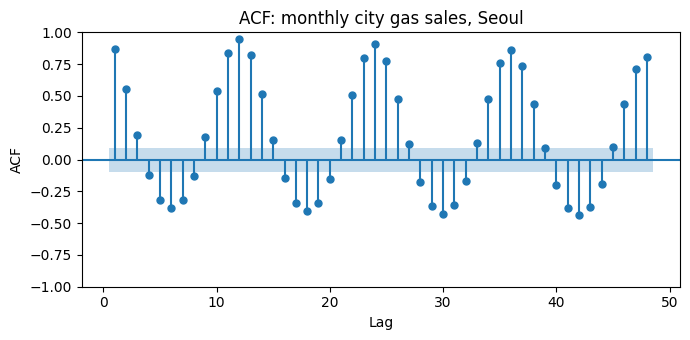

95% band = ± 0.0943


In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.5))
plot_acf(
    df["y"],
    lags=48,
    ax=ax,
    zero=False,          # omit lag-0 (always = 1)
    bartlett_confint=False,
)
ax.set(xlabel="Lag", ylabel="ACF",
       title="ACF: monthly city gas sales, Seoul")
plt.tight_layout(); plt.show()
print("95% band = ±", round(1.96 / np.sqrt(len(df)), 4))

### [Ch3 Slides 6, 8] Box-Cox λ: MLE(scipy)와 Guerrero(coreforecast)
판단 규칙(Ch3 Slide 8): λ를 0.5 단위로 반올림 → λ≈0이면 로그 변환.

In [ ]:
y = df.set_index("ds")["y"]

y_transformed, lam = boxcox(y)                                   # Slide 6: MLE
print(f"Optimal lambda (MLE): {lam:.3f}")
lam_g = boxcox_lambda(y, method="guerrero", season_length=12)    # Slide 8: Guerrero
print(f"Guerrero lambda: {lam_g:.3f}")

# 같은 함수를 훈련 구간(앞 80%, 346개월)에 적용해도 결론이 같은지 확인
y_tr = y.iloc[:round(len(y) * 0.8)]
print(f"[train {len(y_tr)}] MLE lambda: {boxcox(y_tr)[1]:.3f}, "
      f"Guerrero lambda: {boxcox_lambda(y_tr, method='guerrero', season_length=12):.3f}")

Optimal lambda (MLE): 0.299
Guerrero lambda: -0.041
[train 346] MLE lambda: 0.286, Guerrero lambda: -0.077


### [Ch3 Slide 7] 변환 전·후 비교 (로그 변환은 Ch5 Slide 56과 같이 `np.log`)

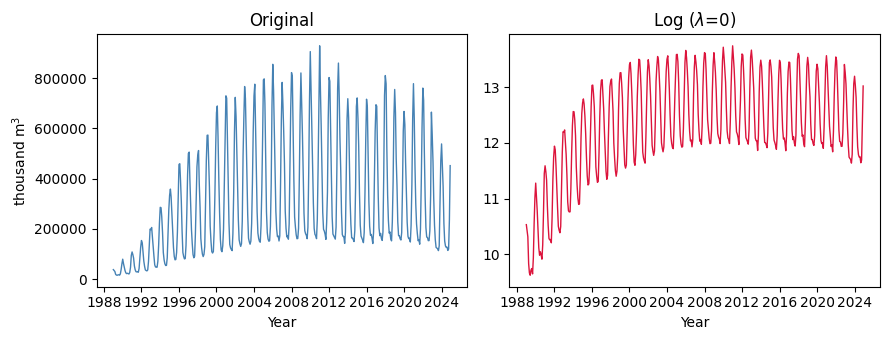

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].plot(y.index, y, lw=1, color="steelblue")
axes[0].set(title="Original", xlabel="Year", ylabel="thousand m$^3$")
axes[1].plot(y.index, np.log(y), lw=1, color="crimson")
axes[1].set(title="Log ($\\lambda$=0)", xlabel="Year")
plt.tight_layout(); plt.show()

### [Ch3 Slide 45] 추세·계절성 강도 (로그 척도)

In [ ]:
def trend_strength(series, period=12, robust=True):
    res = STL(series, period=period, robust=robust).fit()
    var_R  = np.var(res.resid)
    var_TR = np.var(res.trend + res.resid)
    return max(0, 1 - var_R / var_TR)

def season_strength(series, period=12, robust=True):
    res = STL(series, period=period, robust=robust).fit()
    var_R  = np.var(res.resid)
    var_SR = np.var(res.seasonal + res.resid)
    return max(0, 1 - var_R / var_SR)

Ft = trend_strength(np.log(y), period=12)
Fs = season_strength(np.log(y), period=12)
print(f"F_T = {Ft:.3f},  F_S = {Fs:.3f}")

F_T = 0.990,  F_S = 0.989


# 문제 2(2) 다섯 모형의 rolling forecast origin 평가
- 훈련 346개월(1989.01–2017.10), 검증 H = 86개월(2017.11–2024.12), 예측 시차 h = H/2 = 43
- 모든 모형은 로그 척도에서 적합(Ch5 Slide 56), 95% PI는 모형 기반(`level=[95]`)으로 통일
- 기점: step size = 1, 43개월 앞이 모두 관측되는 44개(2017.10–2021.05)

In [ ]:
H = round(len(df) * 0.2)          # 검증 시계열 길이
h = H // 2                        # 예측 시차
train = df.iloc[:-H][["unique_id", "ds", "y"]]
test  = df.iloc[-H:][["unique_id", "ds", "y"]]
df_log = df[["unique_id", "ds", "y"]].assign(y=lambda x: np.log(x["y"]))
print(f"H = {H}, h = {h} | train {train['ds'].iloc[0]:%Y-%m}~{train['ds'].iloc[-1]:%Y-%m} ({len(train)})"
      f" | test {test['ds'].iloc[0]:%Y-%m}~{test['ds'].iloc[-1]:%Y-%m} ({len(test)})")

H = 86, h = 43 | train 1989-01~2017-10 (346) | test 2017-11~2024-12 (86)


### [Ch5 Slide 77, Ch8 Slide 21] Seasonal naive, ETS(ZZZ): `cross_validation`

In [ ]:
sf = StatsForecast(
    models=[SeasonalNaive(12),
            AutoETS(model="ZZZ", season_length=12, alias="ETS")],
    freq="MS")
cv_df = sf.cross_validation(
    h=h, df=df_log,
    step_size=1, test_size=H,
    level=[95]
)
print(cv_df["cutoff"].nunique(), "origins:",
      f"{cv_df['cutoff'].min():%Y-%m} ~ {cv_df['cutoff'].max():%Y-%m}")

44 origins: 2017-10 ~ 2021-05


### [Ch8 Slide 46] 첫 기점과 마지막 기점에서 AutoETS(ZZZ)가 선택한 모형

In [ ]:
for cutoff in [cv_df["cutoff"].min(), cv_df["cutoff"].max()]:
    sf_e = StatsForecast(models=[AutoETS(model="ZZZ", season_length=12, alias="ETS")],
                         freq="MS")
    sf_e.fit(df_log.loc[df_log["ds"] <= cutoff])
    print(f"{cutoff:%Y-%m}:", sf_e.fitted_[0, 0].model_["method"])

2017-10: ETS(A,N,A)
2021-05: ETS(M,Ad,A)


### [Ch5 Slides 59–61] STL-계절조정 + naive / drift / damped Holt
5.7절 코드를 각 기점마다 다시 실행한다(STL을 기점마다 새로 적용). 계절조정 계열은 Naive / RandomWalkWithDrift / AutoETS(model="AAN", damped=True)로, 계절 성분은 SeasonalNaive(12)로 예측한 뒤 점예측과 구간 경계를 각각 더한다(Slide 61).

In [ ]:
stl_list = []
for cutoff in sorted(cv_df["cutoff"].unique()):
    train_i = df_log.loc[df_log["ds"] <= cutoff]
    stl = STL(train_i["y"].to_numpy(),
              period=12, robust=True)
    res = stl.fit()
    train_df = train_i.assign(
        seasonal=res.seasonal,
        y_adjusted=lambda x: x["y"] - x["seasonal"],
    )
    # Forecast the seasonally adjusted component
    sf_adj = StatsForecast(
        models=[Naive(), RandomWalkWithDrift(),
                AutoETS(model="AAN", damped=True, alias="Damped")],
        freq="MS")
    adj_fcasts = sf_adj.forecast(
        h=h, level=[95],
        df=train_df, target_col="y_adjusted"
    )
    # Forecast the seasonal component
    sf_seasonal = StatsForecast(
        models=[SeasonalNaive(12, alias="Seasonal")], freq="MS"
    )
    seas_fcasts = sf_seasonal.forecast(
        h=h, level=[95],
        df=train_df, target_col="seasonal"
    )
    # Combine
    fcasts = adj_fcasts.merge(
        seas_fcasts, on=["unique_id", "ds"]
    )
    for m, name in [("Naive", "STL_Naive"), ("RWD", "STL_Drift"),
                    ("Damped", "STL_Damped")]:
        for c in ["", "-lo-95", "-hi-95"]:
            fcasts[name + c] = (
                fcasts[m + c] + fcasts["Seasonal" + c]
            )
    keep = ["unique_id", "ds"] + [n + c for n in ["STL_Naive", "STL_Drift", "STL_Damped"]
                                  for c in ["", "-lo-95", "-hi-95"]]
    stl_list.append(fcasts[keep].assign(cutoff=cutoff))
stl_df = pd.concat(stl_list)
print(stl_df.shape)

(1892, 12)


### 결합 및 역변환
로그 척도의 실제값·점예측·구간 경계를 `np.exp`로 되돌린다. 점예측은 단순 역변환(중앙값 예측)이며 편향 보정은 하지 않았다(Ch5 Slide 55).

In [ ]:
cv_all = cv_df.merge(stl_df, on=["unique_id", "ds", "cutoff"])
cols = [c for c in cv_all.columns if c not in ("unique_id", "ds", "cutoff")]
cv_all[cols] = np.exp(cv_all[cols])
models = ["SeasonalNaive", "STL_Naive", "STL_Drift", "STL_Damped", "ETS"]
print(cv_all.shape)

(1892, 19)


### [Ch5 Slides 66–67, 77; Ch8 Slide 21] 성능 평가 (천㎥ 척도)
44개 기점 × 43개 시차를 합쳐 계산(cutoff 열 삭제, Slide 77). MASE 분모는 훈련 시계열(Slide 67 `train_df=train_df`)의 계절 naive(m=12) 오차.

In [ ]:
acc = evaluate(cv_all.drop(columns="cutoff"),
               metrics=[mape, partial(mase, seasonality=12), winkler_score],
               models=models, level=[95], train_df=train)
print(acc.drop(columns="unique_id").round(3).to_string(index=False))

               metric  SeasonalNaive  STL_Naive  STL_Drift  STL_Damped        ETS
                 mape         12.647     12.773     31.111      12.665     12.104
                 mase          1.342      1.364      3.223       1.347      1.253
winkler_score_level95     433287.250 584876.578 743092.539  328356.352 294147.605


### [Ch5 Slides 37, 71] 95% 구간 폭(width95)과 Winkler score의 구성
Winkler score = 구간 폭 (u − ℓ) + 실제값이 구간 밖일 때의 항 (2/α)(ℓ − y) 또는 (2/α)(y − u). 평균 width95(Slide 37)를 빼면 두 번째 항의 평균이 남는다.

In [ ]:
width95 = pd.Series({m: (cv_all[f"{m}-hi-95"] - cv_all[f"{m}-lo-95"]).mean() for m in models})
wk = acc.set_index("metric").loc["winkler_score_level95", models]
print(pd.DataFrame({"mean width95": width95, "Winkler": wk,
                    "penalty": wk - width95}).round(1).to_string())

               mean width95        Winkler      penalty
SeasonalNaive      433287.2  433287.249519          0.0
STL_Naive          584876.6  584876.577791          0.0
STL_Drift          743080.0  743092.538798    12.525677
STL_Damped         327057.6  328356.351956  1298.753841
ETS                274425.5  294147.605142  19722.15384


### [Ch5 Slides 75, 79] 예측 시차 h별 MAPE (Can evaluate accuracy at each horizon h separately)
각 기점(cutoff)의 k번째 행 = k단계 앞 예측.

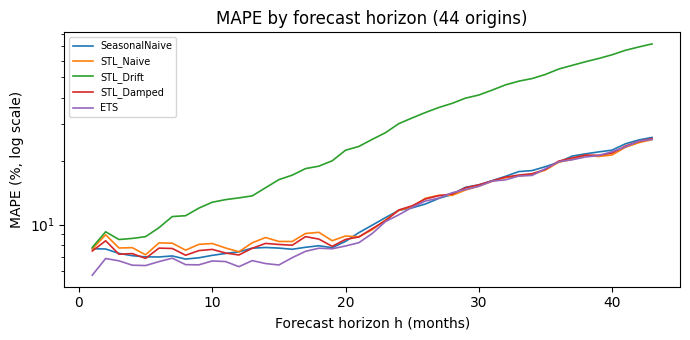

    SeasonalNaive  STL_Naive  STL_Drift  STL_Damped    ETS
1            7.69       7.67       7.81        7.50   5.76
6            7.03       8.20       9.68        7.74   6.68
12           7.44       7.44      13.40        7.19   6.32
24          11.69      11.69      30.13       11.74  11.14
36          19.77      19.77      54.69       20.02  19.89
43          25.92      25.32      71.95       25.59  25.36


In [ ]:
rows = []
for k in range(1, h + 1):
    cv_k = cv_all.groupby("cutoff").nth(k - 1)          # k-step rows
    e = evaluate(cv_k.drop(columns="cutoff"), metrics=[mape], models=models)
    rows.append(e[models].iloc[0].rename(k))
mape_h = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7, 3.5))
for m in models:
    ax.plot(mape_h.index, mape_h[m], lw=1.2, label=m)
ax.set_yscale("log")
ax.set(xlabel="Forecast horizon h (months)", ylabel="MAPE (%, log scale)",
       title="MAPE by forecast horizon (44 origins)")
ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
print(mape_h.loc[[1, 6, 12, 24, 36, 43]].round(2).to_string())

### [Ch5 Slide 75] 긴 시차(h ≥ 36) 예측의 대상 연도별 평균 백분율 오차 p = 100(y − ŷ)/y
음수 = 과대예측.

In [ ]:
cv_all["h"] = cv_all.groupby("cutoff").cumcount() + 1
long_h = cv_all[cv_all["h"] >= 36]
pe = pd.DataFrame({m: 100 * (long_h["y"] - long_h[m]) / long_h["y"] for m in models})
print(pe.groupby(long_h["ds"].dt.year).mean().round(1).to_string())
print("2023-2024년 대상 비율:", round((long_h["ds"].dt.year >= 2023).mean(), 2))

      SeasonalNaive  STL_Naive  STL_Drift  STL_Damped   ETS
ds                                                         
2020           -0.5        0.3      -33.6         0.2  -0.1
2021           -6.5      -10.5      -51.5       -10.3 -11.6
2022           -7.1       -5.9      -43.8        -5.9  -5.0
2023          -39.3      -35.6      -80.9       -36.0 -36.0
2024          -37.2      -37.0      -82.3       -38.7 -39.6
2023-2024년 대상 비율: 0.47


### 첫 기점(2017.10)의 예측과 95% PI (Ch8 Slide 58 그림 형식)

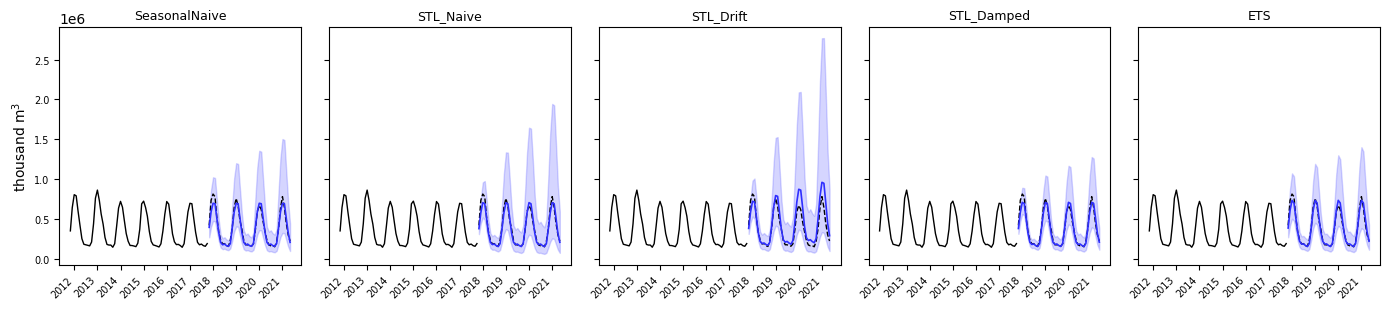

In [ ]:
c0 = cv_all["cutoff"].min()
f0 = cv_all[cv_all["cutoff"] == c0]
hist = df[(df["ds"] > c0 - pd.DateOffset(years=6)) & (df["ds"] <= c0)]
fig, axes = plt.subplots(1, 5, figsize=(14, 3.2), sharey=True)
for ax, m in zip(axes, models):
    ax.plot(hist["ds"], hist["y"], color="black", lw=1)
    ax.plot(f0["ds"], f0["y"], color="black", lw=1, ls="--")
    ax.fill_between(f0["ds"], f0[f"{m}-lo-95"], f0[f"{m}-hi-95"],
                    color="#2f2fff", alpha=0.2)
    ax.plot(f0["ds"], f0[m], color="#2f2fff", lw=1.2)
    ax.set_title(m, fontsize=9)
    ax.tick_params(labelsize=7)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")   # Ch3 Slide 41 방식
axes[0].set_ylabel("thousand m$^3$")
plt.tight_layout(); plt.show()

# 문제 2(3) 최적 예측 모형: ETS (AutoETS, model="ZZZ", season_length=12)
2(2)에서 MAPE, MASE, Winkler score 세 지표 모두 ETS가 가장 좋았으므로 ETS를 최적 모형으로 정하고, 전체 432개월(로그 척도)에 다시 적합한다.

### [Ch8 Slides 47, 52] 전체 자료에 AutoETS 적합: 선택된 모형과 추정 모수
`fit.x` 순서: α, β, γ, φ, l0, b0, s0, s-1, …, s-10 (s-11은 계절 성분의 합이 0이 되도록 정해짐). `states[0]`은 초기 상태 l0, b0, s0, s-1, …, s-11.

In [ ]:
sf_best = StatsForecast(
    models=[AutoETS(model="ZZZ", season_length=12, alias="ETS")],
    freq="MS")
sf_best.fit(df=df_log)
m = sf_best.fitted_[0, 0].model_
print("Selected model:", m["method"])
print(np.round(m["fit"].x, 4))
print("initial states:", np.round(m["states"][0], 4))
print(f"sigma^2 = {m['sigma2']:.6f}  (sigma = {np.sqrt(m['sigma2']):.4f})")
print(f"AICc = {m['aicc']:.2f}")

Selected model: ETS(A,Ad,A)
[ 2.084e-01  2.000e-04  4.773e-01  9.653e-01  9.641e+00  7.170e-02
  7.585e-01  2.493e-01 -2.693e-01 -5.752e-01 -5.435e-01 -5.577e-01
 -5.920e-01 -3.655e-01 -1.383e-01  4.312e-01  6.968e-01]
initial states: [ 9.641   0.0717  0.7585  0.2493 -0.2693 -0.5752 -0.5435 -0.5577 -0.592
 -0.3655 -0.1383  0.4312  0.6968  0.9057]
sigma^2 = 0.010772  (sigma = 0.1038)
AICc = 682.48


### [Ch8 Slide 53] 추정된 성분(로그 척도)

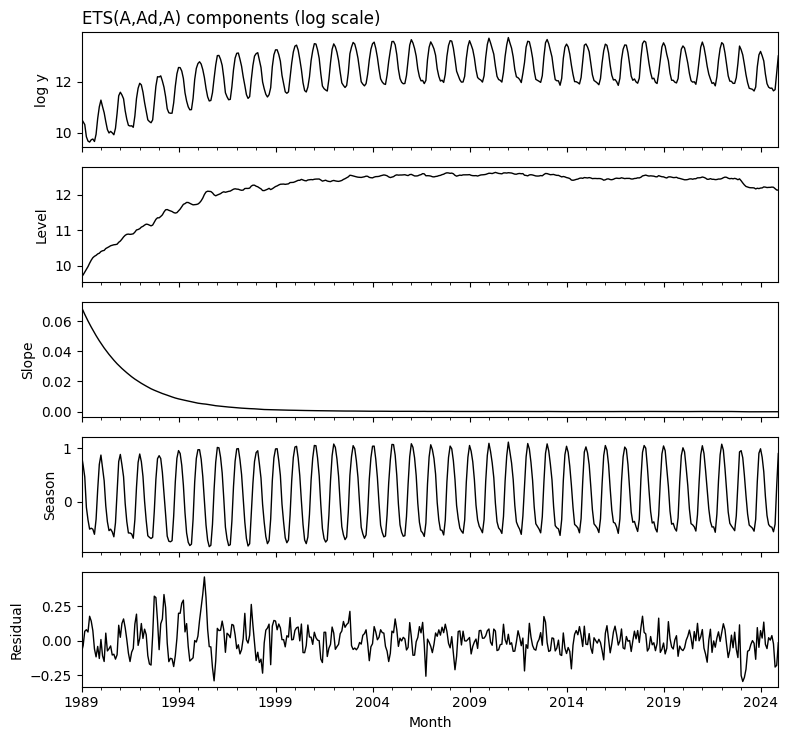

In [ ]:
states = m["states"]                 # row 0 = initial states
comp = pd.DataFrame({
    "log y": df_log["y"].to_numpy(),
    "Level": states[1:, 0],          # l_t
    "Slope": states[1:, 1],          # b_t
    "Season": states[1:, 2],         # s_t
    "Residual": m["residuals"],
    "Month": df_log["ds"].to_numpy(),
}).set_index("Month")
fig, axes = plt.subplots(5, 1, figsize=(8, 7.5), sharex=True)
for ax, column in zip(axes, comp.columns):
    comp[column].plot(ax=ax, color="black", lw=1)
    ax.set_ylabel(column)
axes[0].set_title(m["method"] + " components (log scale)", loc="left")
plt.tight_layout(); plt.show()

### [Ch5 Slides 31–33, Ch8 Slide 56] 적합 잔차의 ACF와 Ljung-Box 검정
적합 잔차 = innovation residual(로그 척도). 시차 ℓ = 2m = 24 (Ch5 Slide 29), 자유도 ℓ − K, K = 추정 모수 수(`fit.x`의 길이, Slide 30).

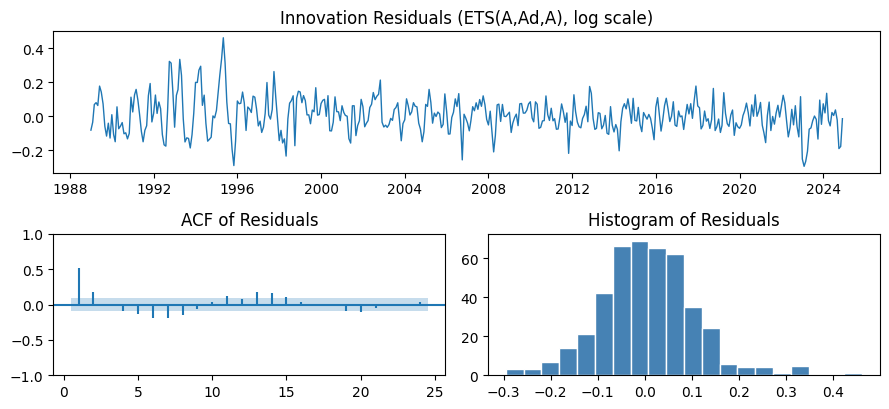

K = 17 | df = 7
     lb_stat  lb_pvalue   bp_stat  bp_pvalue
24  236.1811        0.0  232.1412        0.0
band = ±0.094; lags outside: [(1, 0.511), (2, 0.172), (4, -0.095), (5, -0.133), (6, -0.193), (7, -0.192), (8, -0.148), (11, 0.122), (13, 0.183), (14, 0.169), (15, 0.101), (20, -0.108)]


In [ ]:
resid = df_log.assign(resid=m["residuals"])

fig, axes = plt.subplot_mosaic(
    [["resid", "resid"], ["acf", "hist"]], figsize=(9, 4.2)
)
axes["resid"].plot(resid["ds"], resid["resid"], lw=1)
axes["resid"].set(title="Innovation Residuals (" + m["method"] + ", log scale)")
plot_acf(resid["resid"], lags=24, zero=False,
         bartlett_confint=False, ax=axes["acf"], marker="None")
axes["acf"].set_title("ACF of Residuals")
axes["hist"].hist(resid["resid"], bins=20,
                  color="steelblue", edgecolor="white")
axes["hist"].set_title("Histogram of Residuals")
plt.tight_layout(); plt.show()

# Ljung-Box + Box-Pierce (lag 2m = 24)
K = len(m["fit"].x)
lb_test = acorr_ljungbox(
    resid["resid"], boxpierce=True, lags=[24], model_df=K
)
print("K =", K, "| df =", 24 - K)
print(lb_test.round(4))

acf_r = sm.tsa.acf(resid["resid"], nlags=24, fft=False)
band = 1.96 / np.sqrt(len(resid))
print(f"band = ±{band:.3f}; lags outside:",
      [(k, float(round(acf_r[k], 3))) for k in range(1, 25) if abs(acf_r[k]) > band])

### [Ch5 Slides 49–50] 미래 43개월 점예측과 95% conformal PI
`ConformalIntervals(h=43, n_windows=5)`를 적용하고 `np.exp`로 원자료 단위(천㎥)로 역변환한다.

In [ ]:
ci = ConformalIntervals(h=h, n_windows=5)
sf_conf = StatsForecast(
    models=[AutoETS(model="ZZZ", season_length=12, alias="ETS")],
    freq="MS")
fcasts = sf_conf.forecast(
    df=df_log, h=h, level=[95],
    prediction_intervals=ci
)
final = fcasts[["ds"]].assign(
    point=np.exp(fcasts["ETS"]),
    lo95=np.exp(fcasts["ETS-lo-95"]),
    hi95=np.exp(fcasts["ETS-hi-95"]),
)
pd.set_option("display.max_rows", 100)
print(final.round(1).to_string(index=False))

        ds    point     lo95     hi95
2025-01-01 496026.7 417313.5 589586.7
2025-02-01 423878.1 351859.1 510638.0
2025-03-01 323431.0 293413.9 356518.8
2025-04-01 204598.6 186512.3 224438.7
2025-05-01 143237.6 129699.1 158189.3
2025-06-01 121083.0 110250.1 132980.2
2025-07-01 116484.0 103583.8 130990.9
2025-08-01 115086.5 105836.3 125145.1
2025-09-01 105776.2  87557.2 127786.3
2025-10-01 121825.3 107770.1 137713.5
2025-11-01 248177.3 234033.8 263175.5
2025-12-01 453080.1 382006.5 537377.3
2026-01-01 495306.5 450444.7 544636.4
2026-02-01 423284.0 374316.8 478657.1
2026-03-01 322993.4 276064.9 377899.3
2026-04-01 204331.4 187109.5 223138.4
2026-05-01 143057.0 130017.2 157404.6
2026-06-01 120935.6 108662.3 134595.3
2026-07-01 116347.2 105215.1 128657.2
2026-08-01 114956.0  96393.6 137092.9
2026-09-01 105660.4  82878.4 134705.0
2026-10-01 121696.6  91185.9 162416.2
2026-11-01 247924.2 180345.5 340825.9
2026-12-01 452634.1 347812.1 589047.1
2027-01-01 494835.9 384212.4 637310.4
2027-02-01 4

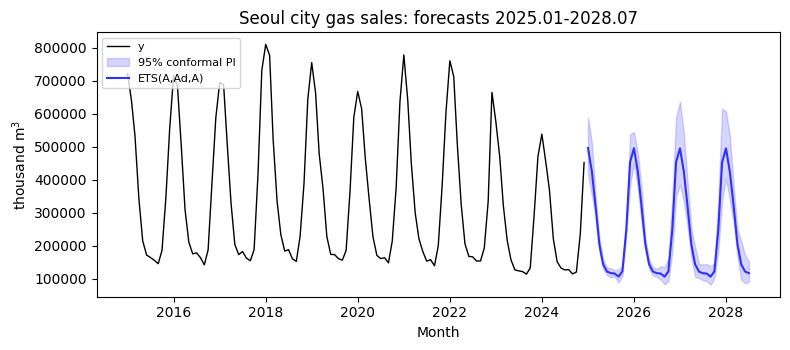

year
2025    2872684.0
2026    2869127.0
2027    2866801.0


In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.6))
hist = df[df["ds"] >= "2015-01-01"]
ax.plot(hist["ds"], hist["y"], color="black", lw=1, label="y")
ax.fill_between(final["ds"], final["lo95"], final["hi95"],
                color="#2f2fff", alpha=0.2, label="95% conformal PI")
ax.plot(final["ds"], final["point"], color="#2f2fff",
        label=m["method"])
ax.set(xlabel="Month", ylabel="thousand m$^3$",
       title="Seoul city gas sales: forecasts 2025.01-2028.07")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

# 참고: 완전한 연도(2025-2027)의 연간 점예측 합계 (천㎥). 구간 경계는 월별로만 해석
annual_fc = final.assign(year=final["ds"].dt.year).groupby("year")["point"].agg(["sum", "count"])
print(annual_fc[annual_fc["count"] == 12]["sum"].round(0).to_string())